# Día 7 — Automatizar el análisis con Pipelines y forecasting económico

**Módulo 3: Machine Learning Aplicado — CEC EPN / Banco Central del Ecuador**

Dos temas para cerrar el módulo:

1. **Automatización de análisis.** Convertir todo lo que hicimos a mano (limpiar, imputar, codificar, escalar, modelar) en un **flujo reproducible**: un `Pipeline` que se entrena una vez, se **guarda en un archivo** y se reutiliza con datos nuevos sin repetir ningún paso a mano.
2. **Forecasting económico.** Pronosticar el valor del **próximo mes** de una serie de tiempo: rezagos, líneas base temporales, división cronológica y validación que respeta el tiempo.

## Cómo está organizada cada parte

| Paso | Qué hacemos |
|---|---|
| 1. Mirar los datos | `head`, tipos y resumen |
| 2. Entender y graficar | ¿Qué queremos automatizar o pronosticar? |
| 3. Preparar | Paso a paso, con el antes y el después |
| 4. Línea base | La regla más simple que hay que superar |
| 5. A mano | Con números pequeños |
| 6. Versión simple con scikit-learn | Pocas líneas comentadas |
| 7. Métricas a mano y con scikit-learn | Train frente a Validation |
| 8. Hiperparámetros, uno por uno | Qué controla cada uno |
| 9. Probar combinaciones con `for` | Contra la línea base |
| 10. Resultado final | Test una sola vez y cómo comunicarlo |

## Los datasets

| Parte | Dataset | Para qué |
|---|---|---|
| A | Credit Risk (Días 3, 5 y 6) y CC GENERAL (Día 4) | Automatizar: Pipeline de clasificación y de clustering, guardarlos y usarlos con datos nuevos |
| B | `macro_mensual_demo.csv`: 144 meses (2014–2025) de 4 indicadores | Pronosticar el índice de actividad del mes siguiente |
| C | Las 4 series de `macro_mensual_demo.csv` | **Comparación final**: todos los modelos en todas las series |

**Importante:** `macro_mensual_demo.csv` es una serie **sintética didáctica** (simulada para practicar). Sirve para aprender el procedimiento; no describe la economía real del Ecuador.

# 0. Librerías

In [1]:
import os
os.environ.setdefault("LOKY_MAX_CPU_COUNT", str(os.cpu_count()))   # evita un aviso en Windows
os.environ["OMP_NUM_THREADS"] = "1"                                  # evita un aviso de K-Means en Windows

from pathlib import Path
import numpy as np                                   # cálculos numéricos
import pandas as pd                                  # tablas
import matplotlib.pyplot as plt                      # gráficos
import joblib                                        # guardar y cargar modelos en archivos

from sklearn.model_selection import train_test_split, TimeSeriesSplit, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.metrics import f1_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

pd.set_option("display.width", 170)
pd.set_option("display.max_columns", 30)
DATA_DIR = Path("datos") if Path("datos").is_dir() else Path("../datos")
SALIDA = Path("resultados_dia7")                     # carpeta donde guardaremos modelos e informes
SALIDA.mkdir(exist_ok=True)
for f in ["credit_risk_dataset.csv", "CC_GENERAL.csv", "macro_mensual_demo.csv"]:
    print("Encontrado" if (DATA_DIR / f).exists() else "FALTA", "→", (DATA_DIR / f).resolve())

Encontrado → C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\credit_risk_dataset.csv
Encontrado → C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\CC_GENERAL.csv
Encontrado → C:\Users\Usuario iTC\Desktop\modulo3_ml\datos\macro_mensual_demo.csv


# Parte A · Automatizar el análisis con Pipelines

**El problema.** Un analista de riesgo recibe cada semana un archivo con solicitudes de préstamo nuevas y debe estimar cuáles caerán en impago. Si cada semana repite a mano «rellenar faltantes, codificar categorías, aplicar el modelo», tarde o temprano se equivocará (por ejemplo, rellenando con la mediana de los datos nuevos en lugar de la de Train). Un **Pipeline** guarda **todos los pasos y todo lo aprendido** en un solo objeto.

## A.1 Mirar los datos

In [2]:
cr = pd.read_csv(DATA_DIR / "credit_risk_dataset.csv")
cr = cr[(cr["person_age"] <= 100) & ~(cr["person_emp_length"] > 60)].drop_duplicates().reset_index(drop=True)   # limpieza del Día 3
y = cr.pop("loan_status")                                                 # 1 = impago
CAT = ["person_home_ownership", "loan_intent", "loan_grade", "cb_person_default_on_file"]
NUM = [c for c in cr.columns if c not in CAT]
X_tr, X_tmp, y_tr, y_tmp = train_test_split(cr, y, test_size=0.30, random_state=42, stratify=y)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=42, stratify=y_tmp)
print("Train / Validation / Test:", len(X_tr), len(X_va), len(X_te))
print("Faltantes en Train:", X_tr.isna().sum()[lambda s: s > 0].to_dict())
X_tr.head()

Train / Validation / Test: 22686 4861 4862
Faltantes en Train: {'person_emp_length': 616, 'loan_int_rate': 2197}


,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
27189,32,131000,MORTGAGE,2.0,DEBTCONSOLIDATION,B,11200,10.25,0.09,N,5
7695,23,30000,RENT,0.0,VENTURE,B,7000,12.69,0.23,N,2
2580,23,35000,RENT,4.0,PERSONAL,C,3000,13.85,0.09,N,3
28610,30,54000,RENT,2.0,HOMEIMPROVEMENT,E,5000,15.13,0.09,N,7
9742,23,64000,MORTGAGE,4.0,VENTURE,A,5550,7.29,0.09,N,4


## A.2 La forma manual: cada paso por separado

Así lo hicimos en los primeros días. Cada paso **aprende** algo de Train (`fit`) y luego **se aplica** a cada tabla (`transform`). Hay que repetir la cadena **en el mismo orden** para Validation, Test y cada archivo nuevo.

In [3]:
# Paso 1: rellenar faltantes numéricos con la mediana DE TRAIN
imputador = SimpleImputer(strategy="median").fit(X_tr[NUM])
# Paso 2: One-Hot de las categorías, con las categorías DE TRAIN
codificador = OneHotEncoder(handle_unknown="ignore", sparse_output=False).fit(X_tr[CAT])
# Paso 3: el modelo
def preparar_a_mano(X):
    return np.hstack([imputador.transform(X[NUM]), codificador.transform(X[CAT])])
bosque = RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1).fit(preparar_a_mano(X_tr), y_tr)
print("Medianas aprendidas:", dict(zip(NUM, imputador.statistics_.round(2))))
print("F1 Validation (a mano):", round(f1_score(y_va, bosque.predict(preparar_a_mano(X_va))), 3))

Medianas aprendidas: {'person_age': np.float64(26.0), 'person_income': np.float64(55000.0), 'person_emp_length': np.float64(4.0), 'loan_amnt': np.float64(8000.0), 'loan_int_rate': np.float64(10.99), 'loan_percent_income': np.float64(0.15), 'cb_person_cred_hist_length': np.float64(4.0)}
F1 Validation (a mano): 0.831


**El error típico.** Llega un archivo nuevo, por ejemplo con solicitudes de grados de riesgo D a G, y alguien, con apuro, ajusta el imputador **con ese archivo** en lugar de usar el de Train. El resultado cambia sin que nadie lo note:

In [4]:
nuevo_archivo = X_va[X_va["loan_grade"].isin(["D", "E", "F", "G"])]      # un lote de solicitudes más riesgosas
imputador_malo = SimpleImputer(strategy="median").fit(nuevo_archivo[NUM])   # ¡aprende la mediana del archivo nuevo!
print("Mediana de la tasa en Train:", imputador.statistics_[NUM.index("loan_int_rate")].round(2),
      "| en el archivo nuevo:", imputador_malo.statistics_[NUM.index("loan_int_rate")].round(2))
X_malo = np.hstack([imputador_malo.transform(nuevo_archivo[NUM]), codificador.transform(nuevo_archivo[CAT])])
cambian = int((bosque.predict(X_malo) != bosque.predict(preparar_a_mano(nuevo_archivo))).sum())
print(f"Solicitudes del lote: {len(nuevo_archivo)} · sin tasa: {int(nuevo_archivo['loan_int_rate'].isna().sum())} · predicciones que cambian: {cambian}")

Mediana de la tasa en Train: 10.99 | en el archivo nuevo: 15.65


Solicitudes del lote: 759 · sin tasa: 67 · predicciones que cambian: 3


Las solicitudes sin tasa reciben una tasa inventada distinta según quién ejecute el análisis, y algunas decisiones cambian. El procedimiento ya **no es reproducible**. Con muchos pasos y muchas personas, este tipo de error es inevitable si todo se hace a mano.

## A.3 La versión simple con scikit-learn: un Pipeline

| Pieza | Qué hace |
|---|---|
| `ColumnTransformer` | Aplica **pasos distintos a columnas distintas** (imputar los números, codificar las categorías) y junta el resultado |
| `Pipeline` | Encadena pasos **en orden**; el último es el modelo |
| `fit` del Pipeline | Ajusta cada paso **con Train**, en orden, pasando el resultado al siguiente |
| `predict` del Pipeline | Aplica cada paso ya aprendido y luego el modelo, **sin volver a aprender nada** |

In [5]:
preparar = ColumnTransformer([
    ("numericas", SimpleImputer(strategy="median"), NUM),                                       # paso para los números
    ("categorias", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT)])         # paso para las categorías
flujo = Pipeline([("preparar", preparar),
                  ("modelo", RandomForestClassifier(n_estimators=200, max_depth=12, random_state=42, n_jobs=-1))])
flujo.fit(X_tr, y_tr)                                                     # UNA línea: aprende todo con Train
print("F1 Train:", round(f1_score(y_tr, flujo.predict(X_tr)), 3), "| F1 Validation:", round(f1_score(y_va, flujo.predict(X_va)), 3))
flujo

F1 Train: 0.848 | F1 Validation: 0.831


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparar', ...), ('modelo', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](11,)","['person_age','person_income','person_home_ownership',..., 'loan_percent_income','cb_person_default_on_file', 'cb_person_cred_hist_length']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,11
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numericas', ...), ('categorias', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dr

Mismo resultado que la forma manual, en una línea, y sin posibilidad de mezclar medianas. Podemos **mirar dentro** del Pipeline: qué aprendió cada paso y cómo quedan los datos después de prepararlos.

In [6]:
print("Pasos:", list(flujo.named_steps))
print("Medianas que aprendió:", flujo.named_steps["preparar"].named_transformers_["numericas"].statistics_.round(2))
preparado = pd.DataFrame(flujo.named_steps["preparar"].transform(X_va.head(3)),
                         columns=flujo.named_steps["preparar"].get_feature_names_out())
print("\nAsí llegan 3 préstamos de Validation al modelo (", preparado.shape[1], "columnas ):")
preparado.round(2)

Pasos: ['preparar', 'modelo']
Medianas que aprendió: [2.600e+01 5.500e+04 4.000e+00 8.000e+03 1.099e+01 1.500e-01 4.000e+00]

Así llegan 3 préstamos de Validation al modelo ( 26 columnas ):


,numericas__person_age,numericas__person_income,numericas__person_emp_length,numericas__loan_amnt,numericas__loan_int_rate,numericas__loan_percent_income,numericas__cb_person_cred_hist_length,categorias__person_home_ownership_MORTGAGE,categorias__person_home_ownership_OTHER,categorias__person_home_ownership_OWN,categorias__person_home_ownership_RENT,categorias__loan_intent_DEBTCONSOLIDATION,categorias__loan_intent_EDUCATION,categorias__loan_intent_HOMEIMPROVEMENT,categorias__loan_intent_MEDICAL,categorias__loan_intent_PERSONAL,categorias__loan_intent_VENTURE,categorias__loan_grade_A,categorias__loan_grade_B,categorias__loan_grade_C,categorias__loan_grade_D,categorias__loan_grade_E,categorias__loan_grade_F,categorias__loan_grade_G,categorias__cb_person_default_on_file_N,categorias__cb_person_default_on_file_Y
0,39.0,21600.0,0.0,6000.0,6.03,0.28,12.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,22.0,28800.0,2.0,10000.0,16.49,0.35,4.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,39.0,38500.0,0.0,3000.0,10.99,0.08,16.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


## A.4 Los hiperparámetros de un Pipeline

Cada paso tiene sus hiperparámetros y se llaman **paso__hiperparámetro** (dos guiones bajos). Se pueden leer con `get_params()` y cambiar con `set_params()`, igual que en la búsqueda del Día 6.

In [7]:
params = flujo.get_params()
print("Algunos nombres:", [k for k in params if k.startswith("modelo__")][:6])
print("Estrategia del imputador:", params["preparar__numericas__strategy"])
filas = []
for prof in [4, 8, 12, 20]:
    flujo.set_params(modelo__max_depth=prof).fit(X_tr, y_tr)              # cambiar un hiperparámetro y reentrenar todo
    filas.append({"modelo__max_depth": prof, "F1 Train": f1_score(y_tr, flujo.predict(X_tr)), "F1 Validation": f1_score(y_va, flujo.predict(X_va))})
pd.DataFrame(filas).round(3)

Algunos nombres: ['modelo__bootstrap', 'modelo__ccp_alpha', 'modelo__class_weight', 'modelo__criterion', 'modelo__max_depth', 'modelo__max_features']
Estrategia del imputador: median


,modelo__max_depth,F1 Train,F1 Validation
0,4,0.692,0.698
1,8,0.814,0.821
2,12,0.848,0.831
3,20,0.943,0.836


In [8]:
flujo.set_params(modelo__max_depth=12).fit(X_tr, y_tr)                   # nos quedamos con profundidad 12
print("Modelo final — F1 Validation:", round(f1_score(y_va, flujo.predict(X_va)), 3), "| F1 Test (una vez):", round(f1_score(y_te, flujo.predict(X_te)), 3))

Modelo final — F1 Validation: 0.831 | F1 Test (una vez): 0.817


## A.5 Guardar el flujo y usarlo con solicitudes nuevas

`joblib.dump` guarda el Pipeline **completo** (medianas, categorías y los 200 árboles) en un archivo. Otro día, en otra computadora, `joblib.load` lo recupera listo para usar: no hay que volver a entrenar ni recordar ningún paso.

In [9]:
archivo_modelo = SALIDA / "modelo_impago.joblib"
joblib.dump(flujo, archivo_modelo)                                        # guardar
print("Guardado:", archivo_modelo.resolve(), f"({archivo_modelo.stat().st_size / 1e6:.1f} MB)")

modelo_cargado = joblib.load(archivo_modelo)                              # cargar (por ejemplo, la próxima semana)
solicitudes = pd.DataFrame([
    {"person_age": 25, "person_income": 18000, "person_home_ownership": "RENT", "person_emp_length": 1.0, "loan_intent": "MEDICAL",
     "loan_grade": "D", "loan_amnt": 9000, "loan_int_rate": 16.5, "loan_percent_income": 0.50, "cb_person_default_on_file": "Y", "cb_person_cred_hist_length": 3},
    {"person_age": 41, "person_income": 85000, "person_home_ownership": "MORTGAGE", "person_emp_length": 12.0, "loan_intent": "HOMEIMPROVEMENT",
     "loan_grade": "A", "loan_amnt": 6000, "loan_int_rate": np.nan, "loan_percent_income": 0.07, "cb_person_default_on_file": "N", "cb_person_cred_hist_length": 14}])
solicitudes["prob_impago"] = modelo_cargado.predict_proba(solicitudes[NUM + CAT])[:, 1].round(3)   # probabilidad de impago
solicitudes["decision"] = np.where(solicitudes["prob_impago"] >= 0.5, "revisar", "aprobar")
solicitudes[["person_age", "person_income", "loan_grade", "loan_percent_income", "loan_int_rate", "prob_impago", "decision"]]

Guardado: C:\Users\Usuario iTC\Desktop\modulo3_ml\notebooks\resultados_dia7\modelo_impago.joblib (16.6 MB)


,person_age,person_income,loan_grade,loan_percent_income,loan_int_rate,prob_impago,decision
0,25,18000,D,0.50,16.5,0.983,revisar
1,41,85000,A,0.07,NaN,0.040,aprobar


La segunda solicitud **no trae tasa de interés** (`NaN`), y el flujo la rellenó solo con la mediana **de Train** que guardó. Nadie tuvo que recordar ese paso.

## A.6 El mismo principio para el clustering del Día 4

Un banco quiere asignar cada mes a sus clientes nuevos a los segmentos del Día 4. El flujo: logaritmo de los montos → estandarizar → K-Means. El logaritmo no aprende nada, pero también va dentro, con `FunctionTransformer`.

In [10]:
cc = pd.read_csv(DATA_DIR / "CC_GENERAL.csv").dropna(subset=["CREDIT_LIMIT"])
VARS = ["BALANCE", "PURCHASES", "ONEOFF_PURCHASES", "INSTALLMENTS_PURCHASES", "CASH_ADVANCE",
        "PURCHASES_FREQUENCY", "CREDIT_LIMIT", "PAYMENTS", "PRC_FULL_PAYMENT"]
MONTOS = VARS[:5] + ["CREDIT_LIMIT", "PAYMENTS"]
log_montos = ColumnTransformer([("log", FunctionTransformer(np.log1p), MONTOS)], remainder="passthrough")   # log solo a los montos
segmentador = Pipeline([("log", log_montos), ("escalar", StandardScaler()), ("kmeans", KMeans(n_clusters=4, n_init=20, random_state=42))])
segmentador.fit(cc[VARS])                                                 # aprende log → medias → centros

# Nombres con la regla del Día 4 (sobre los centros, en desviaciones)
centros = pd.DataFrame(segmentador.named_steps["kmeans"].cluster_centers_, columns=MONTOS + [v for v in VARS if v not in MONTOS])
pend = list(centros.index); NOMBRES = {}
for var, nom in [("PRC_FULL_PAYMENT", "Totaleros"), ("CASH_ADVANCE", "Usuarios de avances"), ("PURCHASES", "Compradores que financian")]:
    s = centros.loc[pend, var].idxmax(); NOMBRES[s] = nom; pend.remove(s)
NOMBRES[pend[0]] = "Poco activos"
print("Clientes por segmento:", pd.Series(segmentador.named_steps["kmeans"].labels_).map(NOMBRES).value_counts().to_dict())

joblib.dump({"modelo": segmentador, "nombres": NOMBRES}, SALIDA / "segmentador_tarjeta.joblib")       # guardar modelo y nombres juntos
paquete = joblib.load(SALIDA / "segmentador_tarjeta.joblib")
nuevos = pd.DataFrame([[2500, 0, 0, 0, 3000, 0.0, 4000, 900, 0.0], [50, 800, 200, 600, 0, 1.0, 5000, 850, 1.0], [150, 100, 0, 100, 0, 0.3, 1500, 200, 0.0]],
                      columns=VARS, index=["Ana", "Beto", "Carla"])
nuevos["segmento"] = [paquete["nombres"][g] for g in paquete["modelo"].predict(nuevos[VARS])]
nuevos

Clientes por segmento: {'Compradores que financian': 2770, 'Poco activos': 2444, 'Usuarios de avances': 2438, 'Totaleros': 1297}


,BALANCE,PURCHASES,ONEOFF_PURCHASES,INSTALLMENTS_PURCHASES,CASH_ADVANCE,PURCHASES_FREQUENCY,CREDIT_LIMIT,PAYMENTS,PRC_FULL_PAYMENT,segmento
Ana,2500,0,0,0,3000,0.0,4000,900,0.0,Usuarios de avances
Beto,50,800,200,600,0,1.0,5000,850,1.0,Totaleros
Carla,150,100,0,100,0,0.3,1500,200,0.0,Poco activos


Los mismos tres clientes del Día 4 y la misma respuesta (avances, totaleros, poco activos), ahora con **una sola línea** de `predict` sobre los datos en dólares.

## A.7 Automatizar un informe completo

Juntamos todo en **una función** que recibe un archivo de solicitudes y devuelve un informe: cuántas solicitudes, cuántas a revisar, la probabilidad promedio por grado y un CSV con la decisión de cada una. Cada semana basta con llamarla.

In [11]:
def informe_semanal(archivo_csv, archivo_modelo=SALIDA / "modelo_impago.joblib", umbral=0.5):
    # 1) cargar el modelo guardado y los datos nuevos
    modelo = joblib.load(archivo_modelo)
    nuevas = pd.read_csv(archivo_csv)
    # 2) puntuar (el Pipeline hace toda la preparación)
    nuevas["prob_impago"] = modelo.predict_proba(nuevas[NUM + CAT])[:, 1]
    nuevas["decision"] = np.where(nuevas["prob_impago"] >= umbral, "revisar", "aprobar")
    # 3) guardar el detalle y devolver un resumen
    salida = SALIDA / ("puntuado_" + Path(archivo_csv).name)
    nuevas.to_csv(salida, index=False)
    resumen = nuevas.groupby("loan_grade").agg(solicitudes=("decision", "size"), a_revisar=("decision", lambda d: (d == "revisar").sum()),
                                               prob_promedio=("prob_impago", "mean")).round(3)
    print(f"{len(nuevas)} solicitudes · {(nuevas['decision'] == 'revisar').sum()} a revisar · detalle en {salida}")
    return resumen

# Simulamos el archivo de «esta semana» con 500 préstamos de Test (sin la respuesta)
X_te.sample(500, random_state=7).to_csv(SALIDA / "solicitudes_semana.csv", index=False)
informe_semanal(SALIDA / "solicitudes_semana.csv")

500 solicitudes · 75 a revisar · detalle en resultados_dia7/puntuado_solicitudes_semana.csv


,solicitudes,a_revisar,prob_promedio
loan_grade,,,
A,164,18,0.143
B,168,22,0.197
C,97,6,0.178
D,52,19,0.493
E,16,9,0.626
F,3,1,0.504


**Resultado de la Parte A.** El análisis ya no depende de que alguien repita los pasos: el Pipeline guarda la preparación y el modelo, `joblib` los conserva en un archivo y una función produce el informe. Esto es **automatizar un análisis**: reproducible, sin fugas y fácil de auditar. La probabilidad promedio de impago pasa de ≈ 0,14–0,20 en los grados A a C a ≈ 0,5–0,6 en los grados D a F, como esperaría un analista de crédito.

# Parte B · Forecasting: pronosticar el índice de actividad del próximo mes

**El problema.** Cada mes, el equipo de coyuntura quiere estimar el índice de actividad **del mes siguiente** con la información disponible hoy. Es una **regresión** (la respuesta es un número), pero con una diferencia clave: los datos están **ordenados en el tiempo** y el futuro no se puede usar para predecir el pasado.

## B.1 Mirar los datos

In [12]:
macro = pd.read_csv(DATA_DIR / "macro_mensual_demo.csv", parse_dates=["fecha"]).set_index("fecha")
print("Filas:", len(macro), "| desde", macro.index.min().date(), "hasta", macro.index.max().date())
print("Tipo de dato:", macro["tipo_dato"].unique())
macro = macro.drop(columns="tipo_dato")
macro.head()

Filas: 144 | desde 2014-01-01 hasta 2025-12-01
Tipo de dato: <StringArray>
['SINTETICO_DIDACTICO']
Length: 1, dtype: str


,precio_petroleo_usd,inflacion_interanual_pct,exportaciones_mill,indice_actividad
fecha,,,,
2014-01-01,49.79,2.37,810.21,92.32
2014-02-01,49.91,3.38,851.78,90.46
2014-03-01,43.35,2.23,803.91,90.89
2014-04-01,55.58,2.36,955.40,91.79
2014-05-01,60.81,3.04,907.31,91.28


| Columna | Qué es (en la simulación) |
|---|---|
| `precio_petroleo_usd` | Precio del barril, en dólares |
| `inflacion_interanual_pct` | Inflación de los últimos 12 meses, en % |
| `exportaciones_mill` | Exportaciones del mes, en millones de dólares |
| `indice_actividad` | Índice de actividad económica (nuestro objetivo) |

**Serie de tiempo frente a tabla transversal.** En Credit Risk cada fila era un préstamo distinto y el orden no importaba. Aquí cada fila es **un mes** y el orden es todo: enero de 2020 viene después de diciembre de 2019 y lo que pasó en diciembre ayuda a explicar enero.

**Primer control: la frecuencia.** Antes de crear rezagos hay que verificar que no falten meses; si faltara uno, «el mes anterior» sería en realidad dos meses atrás.

In [13]:
esperadas = pd.date_range(macro.index.min(), macro.index.max(), freq="MS")      # todos los inicios de mes
print("Meses esperados:", len(esperadas), "| meses en el archivo:", len(macro), "| faltantes:", len(esperadas.difference(macro.index)))
print("Valores faltantes:", int(macro.isna().sum().sum()))

Meses esperados: 144 | meses en el archivo: 144 | faltantes: 0
Valores faltantes: 0


## B.2 Entender y graficar: tendencia, estacionalidad y ruido

Una serie económica suele combinar tres componentes:

- **Tendencia:** la dirección de largo plazo (sube, baja). La vemos con un **promedio móvil de 12 meses**, que borra los altibajos del año.
- **Estacionalidad:** un patrón que se repite cada año (meses fuertes y débiles). La vemos promediando cada mes del calendario.
- **Ruido:** lo que queda, impredecible.

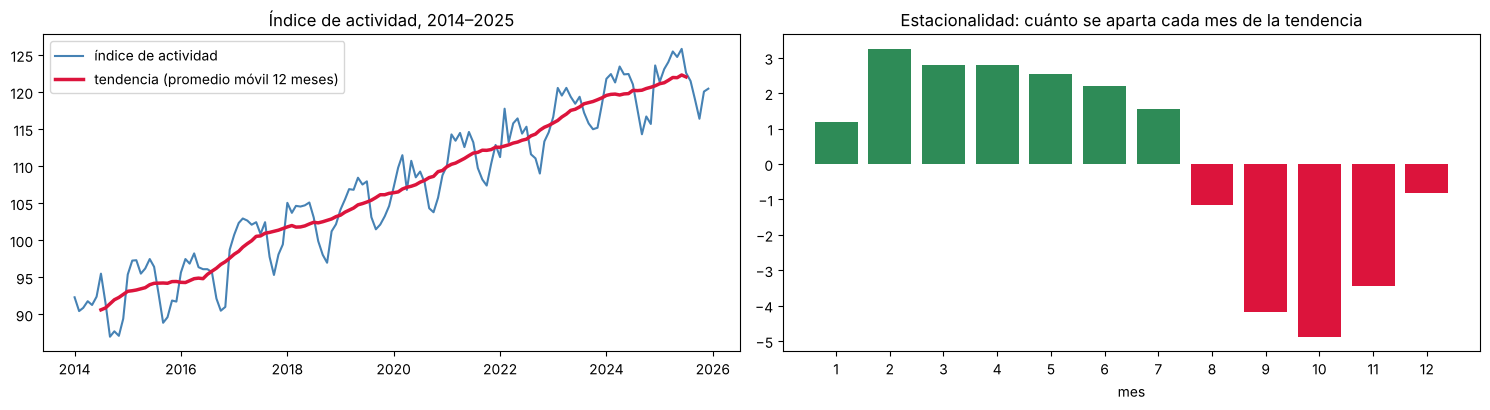

Efecto estacional por mes: {1: 1.2, 2: 3.3, 3: 2.8, 4: 2.8, 5: 2.6, 6: 2.2, 7: 1.6, 8: -1.2, 9: -4.2, 10: -4.9, 11: -3.4, 12: -0.8}


In [14]:
act = macro["indice_actividad"]
tendencia = act.rolling(12, center=True).mean()                       # promedio de 12 meses alrededor de cada mes
estacional = (act - tendencia).groupby(act.index.month).mean()        # cuánto se aparta cada mes de la tendencia, en promedio
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
ax[0].plot(act, color="steelblue", label="índice de actividad"); ax[0].plot(tendencia, color="crimson", lw=2.5, label="tendencia (promedio móvil 12 meses)")
ax[0].set(title="Índice de actividad, 2014–2025"); ax[0].legend()
ax[1].bar(range(1, 13), estacional.values, color=["crimson" if v < 0 else "seagreen" for v in estacional])
ax[1].set(title="Estacionalidad: cuánto se aparta cada mes de la tendencia", xticks=range(1, 13), xlabel="mes")
plt.tight_layout(); plt.show()
print("Efecto estacional por mes:", estacional.round(1).to_dict())

**Interpretación.** La serie tiene una **tendencia creciente** (con una caída marcada alrededor de 2020) y una **estacionalidad** clara: agosto a noviembre están por debajo de su tendencia (octubre, casi 5 puntos); febrero a julio, por encima. Un buen pronóstico debe capturar las dos cosas.

## B.3 Preparar: rezagos y objetivo futuro, paso a paso

Un modelo de Machine Learning necesita una **tabla**: columnas `X` y una respuesta `y`. Con una serie la construimos así, parados en cada mes **t** (el «origen» del pronóstico):

- **Rezagos** (*lags*): los valores conocidos hoy: el del mes t, el de t − 1, el de t − 2… y el de t − 11 (hace un año respecto al mes que queremos pronosticar).
- **Objetivo:** el valor del mes **t + 1**, que todavía no conocemos.

En pandas, `shift(k)` mueve la serie k filas hacia abajo (trae el pasado) y `shift(-1)` la mueve hacia arriba (trae el futuro).

In [15]:
def tabla_rezagos(serie, rezagos=(1, 2, 3, 12)):
    t = pd.DataFrame(index=serie.index)
    for k in rezagos:
        t[f"rezago_{k}"] = serie.shift(k - 1)                 # rezago_1 = valor del mes t (el último conocido); rezago_12 = mes t − 11
    mes_objetivo = (serie.index + pd.offsets.MonthBegin(1)).month
    for m in range(1, 13):
        t[f"mes_{m}"] = (mes_objetivo == m).astype(int)       # 1 en la columna del mes que vamos a pronosticar
    t["objetivo"] = serie.shift(-1)                           # el valor del mes siguiente
    return t

tabla = tabla_rezagos(act)
print("Primeras filas (los NaN aparecen donde no hay historia suficiente):")
tabla[["rezago_1", "rezago_2", "rezago_3", "rezago_12", "mes_2", "objetivo"]].head(13).round(2)

Primeras filas (los NaN aparecen donde no hay historia suficiente):


,rezago_1,rezago_2,rezago_3,rezago_12,mes_2,objetivo
fecha,,,,,,
2014-01-01,92.32,NaN,NaN,NaN,1,90.46
2014-02-01,90.46,92.32,NaN,NaN,0,90.89
2014-03-01,90.89,90.46,92.32,NaN,0,91.79
2014-04-01,91.79,90.89,90.46,NaN,0,91.28
2014-05-01,91.28,91.79,90.89,NaN,0,92.40
2014-06-01,92.40,91.28,91.79,NaN,0,95.51
2014-07-01,95.51,92.40,91.28,NaN,0,91.58
2014-08-01,91.58,95.51,92.40,NaN,0,87.00
2014-09-01,87.00,91.58,95.51,NaN,0,87.73


**Verifica una fila a mano.** En la fila de **enero de 2015** (el origen):

- `rezago_1` = actividad de enero de 2015; `rezago_2` = diciembre de 2014; `rezago_3` = noviembre de 2014; `rezago_12` = febrero de 2014 (el mismo mes que pronosticamos, un año antes).
- `mes_2` = 1 porque pronosticamos **febrero**.
- `objetivo` = actividad de febrero de 2015.

In [16]:
f = pd.Timestamp("2015-01-01")
print("Fila de enero 2015:", tabla.loc[f, ["rezago_1", "rezago_2", "rezago_3", "rezago_12", "objetivo"]].round(2).to_dict())
print("Comprobación con la serie original:",
      {"ene-2015": act["2015-01-01"].round(2), "dic-2014": act["2014-12-01"].round(2), "nov-2014": act["2014-11-01"].round(2),
       "feb-2014": act["2014-02-01"].round(2), "feb-2015 (objetivo)": act["2015-02-01"].round(2)})
tabla = tabla.dropna()                                   # quitamos los primeros 11 meses (sin historia) y el último (sin objetivo)
print("\nFilas útiles:", len(tabla))

Fila de enero 2015: {'rezago_1': 95.39, 'rezago_2': 89.43, 'rezago_3': 87.12, 'rezago_12': 90.46, 'objetivo': 97.27}
Comprobación con la serie original: {'ene-2015': np.float64(95.39), 'dic-2014': np.float64(89.43), 'nov-2014': np.float64(87.12), 'feb-2014': np.float64(90.46), 'feb-2015 (objetivo)': np.float64(97.27)}

Filas útiles: 132


**La regla que no se rompe:** cada columna de `X` usa solo información disponible en el mes t. Si por error usáramos `shift(-1)` en un predictor, el modelo vería el futuro: un error de **fuga** que da métricas excelentes y pronósticos inútiles.

## B.4 División cronológica y líneas base

En una serie **no se mezcla al azar**: Train es el pasado, Validation el período siguiente y Test lo más reciente.

| Parte | Orígenes | Pronostica |
|---|---|---|
| Train | ene-2015 a nov-2021 | feb-2015 a dic-2021 |
| Validation | dic-2021 a nov-2023 | ene-2022 a dic-2023 (24 meses) |
| Test | dic-2023 a nov-2025 | ene-2024 a dic-2025 (24 meses) |

In [17]:
tr = tabla[tabla.index < "2021-12-01"]
va = tabla[(tabla.index >= "2021-12-01") & (tabla.index < "2023-12-01")]
te = tabla[tabla.index >= "2023-12-01"]
COLS = [c for c in tabla.columns if c != "objetivo"]
print("Train:", len(tr), "| Validation:", len(va), "| Test:", len(te))

Train: 84 | Validation: 24 | Test: 24


**Líneas base temporales.** Reglas sin Machine Learning que un modelo **debe** superar:

| Línea base | Pronóstico del mes siguiente | Qué captura |
|---|---|---|
| **Ingenua** | El último valor conocido (`rezago_1`) | La inercia |
| **Estacional ingenua** | El valor del mismo mes, un año antes (`rezago_12`) | La estacionalidad |
| **Promedio móvil de 3** | El promedio de los 3 últimos meses | La inercia, suavizada |

A mano, para pronosticar **enero de 2022** (origen diciembre de 2021):

In [18]:
o = va.iloc[0]
print(f"Real de enero 2022: {o['objetivo']:.2f}")
print(f"Ingenua:            {o['rezago_1']:.2f} → error {abs(o['objetivo'] - o['rezago_1']):.2f}")
print(f"Estacional ingenua: {o['rezago_12']:.2f} → error {abs(o['objetivo'] - o['rezago_12']):.2f}")
pm3 = o[["rezago_1", "rezago_2", "rezago_3"]].mean()
print(f"Promedio móvil 3:   ({o['rezago_1']:.2f} + {o['rezago_2']:.2f} + {o['rezago_3']:.2f}) / 3 = {pm3:.2f} → error {abs(o['objetivo'] - pm3):.2f}")

def lineas_base(t):
    return {"Ingenua": t["rezago_1"], "Estacional ingenua": t["rezago_12"], "Promedio móvil 3": t[["rezago_1", "rezago_2", "rezago_3"]].mean(axis=1)}
print("\nMAE en Validation (24 meses):", {k: round(mean_absolute_error(va["objetivo"], v), 2) for k, v in lineas_base(va).items()})

Real de enero 2022: 111.23
Ingenua:            112.87 → error 1.64
Estacional ingenua: 110.08 → error 1.15
Promedio móvil 3:   (112.87 + 110.36 + 107.39) / 3 = 110.21 → error 1.02

MAE en Validation (24 meses): {'Ingenua': 2.07, 'Estacional ingenua': 3.15, 'Promedio móvil 3': 2.29}


## B.5 El modelo a mano: regresión lineal con un rezago

La regresión del Día 1, ahora con el valor de este mes para predecir el del próximo: $\hat y_{t+1} = a + b\,y_t$. Con mínimos cuadrados:

$$b = \frac{\sum (x - \bar x)(y - \bar y)}{\sum (x - \bar x)^2}, \qquad a = \bar y - b\,\bar x$$

In [19]:
x, yv = tr["rezago_1"].values, tr["objetivo"].values
b = ((x - x.mean()) * (yv - yv.mean())).sum() / ((x - x.mean()) ** 2).sum()
a = yv.mean() - b * x.mean()
print(f"A mano: pronóstico = {a:.2f} + {b:.3f} × (actividad de este mes)")
print(f"Enero 2022: {a:.2f} + {b:.3f} × {o['rezago_1']:.2f} = {a + b * o['rezago_1']:.2f} (real {o['objetivo']:.2f})")
lr1 = LinearRegression().fit(tr[["rezago_1"]], tr["objetivo"])
print(f"scikit-learn: a = {lr1.intercept_:.2f}, b = {lr1.coef_[0]:.3f}")

A mano: pronóstico = 8.11 + 0.923 × (actividad de este mes)
Enero 2022: 8.11 + 0.923 × 112.87 = 112.33 (real 111.23)
scikit-learn: a = 8.11, b = 0.923


Con un solo rezago, el modelo es casi la línea base ingenua (b = 0,92, cerca de 1): no sabe nada de la estacionalidad. Para eso agregamos el rezago de 12 meses y los indicadores del mes.

## B.6 La versión simple con scikit-learn

In [20]:
lineal = LinearRegression()                                  # 1) crear
lineal.fit(tr[COLS], tr["objetivo"])                         # 2) entrenar con el pasado
pred_va = lineal.predict(va[COLS])                           # 3) pronosticar Validation
print("Coeficientes de los rezagos:", dict(zip(COLS[:4], lineal.coef_[:4].round(3))))
print("Efecto de cada mes (respecto al promedio):", dict(zip(range(1, 13), lineal.coef_[4:].round(2))))

Coeficientes de los rezagos: {'rezago_1': np.float64(0.363), 'rezago_2': np.float64(0.312), 'rezago_3': np.float64(0.249), 'rezago_12': np.float64(0.071)}
Efecto de cada mes (respecto al promedio): {1: np.float64(4.34), 2: np.float64(3.63), 3: np.float64(1.78), 4: np.float64(-0.35), 5: np.float64(-0.43), 6: np.float64(-0.36), 7: np.float64(-1.02), 8: np.float64(-2.91), 9: np.float64(-4.62), 10: np.float64(-3.39), 11: np.float64(0.48), 12: np.float64(2.85)}


## B.7 Métricas a mano y con scikit-learn: Train frente a Validation

| Métrica | Fórmula | Se lee como… |
|---|---|---|
| **MAE** | promedio de $|real - pronóstico|$ | Error típico, en puntos del índice |
| **RMSE** | $\sqrt{\text{promedio de } (real - pronóstico)^2}$ | Como el MAE pero castiga más los errores grandes |
| **MAPE** | promedio de $|real - pronóstico| / real$ | Error en porcentaje del valor real |

In [21]:
err = va["objetivo"].values - pred_va
print(f"A mano:       MAE = {np.abs(err).mean():.3f} | RMSE = {np.sqrt((err ** 2).mean()):.3f} | MAPE = {(np.abs(err) / va['objetivo'].values).mean():.2%}")
print(f"scikit-learn: MAE = {mean_absolute_error(va['objetivo'], pred_va):.3f} | RMSE = {np.sqrt(mean_squared_error(va['objetivo'], pred_va)):.3f} | MAPE = {mean_absolute_percentage_error(va['objetivo'], pred_va):.2%}")

def medir(nombre, pred_tr, pred_va):
    return {"modelo": nombre, "MAE_train": mean_absolute_error(tr["objetivo"], pred_tr), "MAE_val": mean_absolute_error(va["objetivo"], pred_va),
            "RMSE_val": np.sqrt(mean_squared_error(va["objetivo"], pred_va))}
filas = [medir(k, lineas_base(tr)[k], v) for k, v in lineas_base(va).items()]
filas.append(medir("Regresión lineal (rezagos + mes)", lineal.predict(tr[COLS]), pred_va))
pd.DataFrame(filas).set_index("modelo").round(3)

A mano:       MAE = 1.286 | RMSE = 1.584 | MAPE = 1.12%
scikit-learn: MAE = 1.286 | RMSE = 1.584 | MAPE = 1.12%


,MAE_train,MAE_val,RMSE_val
modelo,,,
Ingenua,1.896,2.069,2.572
Estacional ingenua,3.176,3.148,3.585
Promedio móvil 3,2.743,2.289,2.796
Regresión lineal (rezagos + mes),1.051,1.286,1.584


**Interpretación.** La regresión lineal tiene el menor MAE en Validation: se equivoca en promedio poco más de 1 punto del índice, contra ≈ 2 de la línea base ingenua. Y su error en Train y en Validation es parecido: no memoriza. La estacional ingenua es la peor aquí porque ignora la tendencia: el mismo mes de hace un año estaba bastante más abajo.

## B.8 Hiperparámetros del forecasting, uno por uno

| Hiperparámetro | Qué controla |
|---|---|
| **Rezagos** | Cuántos meses de historia mira el modelo (1, 3, 6, 12…) |
| **Variables de calendario** | Si incluimos el mes (estacionalidad) |
| **El modelo y sus hiperparámetros** | Lineal; Random Forest con `n_estimators`, `max_depth`, `min_samples_leaf` |
| `TimeSeriesSplit`: `n_splits` | Cuántas validaciones sucesivas |
| `TimeSeriesSplit`: `test_size`, `gap` | Cuántos meses valida cada vuelta y cuántos se saltan entre entrenar y validar |

**Validación cruzada que respeta el tiempo.** La validación cruzada del Día 6 mezcla filas al azar: en una serie, eso entrenaría con el futuro. `TimeSeriesSplit` siempre entrena con el pasado y valida con el período **siguiente**, cada vez con más historia:

In [22]:
dev = pd.concat([tr, va])                                            # Train + Validation (Test sigue aparte)
tscv = TimeSeriesSplit(n_splits=4, test_size=12)                     # 4 vueltas, cada una valida 12 meses
for i, (ie, iv) in enumerate(tscv.split(dev), start=1):
    print(f"Vuelta {i}: entrena {dev.index[ie[0]]:%Y-%m} a {dev.index[ie[-1]]:%Y-%m} ({len(ie)} meses) · valida {dev.index[iv[0]]:%Y-%m} a {dev.index[iv[-1]]:%Y-%m}")

Vuelta 1: entrena 2014-12 a 2019-11 (60 meses) · valida 2019-12 a 2020-11
Vuelta 2: entrena 2014-12 a 2020-11 (72 meses) · valida 2020-12 a 2021-11
Vuelta 3: entrena 2014-12 a 2021-11 (84 meses) · valida 2021-12 a 2022-11
Vuelta 4: entrena 2014-12 a 2022-11 (96 meses) · valida 2022-12 a 2023-11


## B.9 Probar combinaciones con un `for`: rezagos × modelo

Probamos distintas historias (solo el mes anterior; 3 meses; 3 meses + hace un año), con y sin calendario, y dos modelos (lineal y Random Forest). Medimos el MAE promedio de las 4 vueltas de `TimeSeriesSplit`.

In [23]:
recetas = {"1 rezago": ["rezago_1"], "3 rezagos": ["rezago_1", "rezago_2", "rezago_3"],
           "3 rezagos + 12": ["rezago_1", "rezago_2", "rezago_3", "rezago_12"],
           "3 rezagos + 12 + mes": COLS}
modelos = {"Lineal": lambda: LinearRegression(),
           "Random Forest": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=3, random_state=42, n_jobs=-1)}
filas = []
for receta, cols in recetas.items():
    for nombre, crear in modelos.items():
        maes = []
        for ie, iv in tscv.split(dev):
            m = crear().fit(dev.iloc[ie][cols], dev.iloc[ie]["objetivo"])
            maes.append(mean_absolute_error(dev.iloc[iv]["objetivo"], m.predict(dev.iloc[iv][cols])))
        filas.append({"variables": receta, "modelo": nombre, "MAE_cv": np.mean(maes), "desv": np.std(maes)})
base_cv = np.mean([mean_absolute_error(dev.iloc[iv]["objetivo"], dev.iloc[iv]["rezago_1"]) for _, iv in tscv.split(dev)])
print(f"Línea base ingenua, mismas 4 vueltas: MAE = {base_cv:.3f}")
pd.DataFrame(filas).pivot(index="variables", columns="modelo", values="MAE_cv").loc[list(recetas)].round(3)

Línea base ingenua, mismas 4 vueltas: MAE = 2.139


modelo,Lineal,Random Forest
variables,,
1 rezago,2.096,3.147
3 rezagos,2.187,3.292
3 rezagos + 12,1.625,2.444
3 rezagos + 12 + mes,1.297,2.436


**Interpretación.**

- Agregar el rezago de 12 meses y el calendario **baja el error** de la regresión lineal: ahí está la estacionalidad.
- El **Random Forest** es peor que la regresión lineal con cualquier receta. Un bosque predice **promedios de los valores que vio en Train**: no puede pronosticar un índice más alto que cualquiera del pasado. Con una serie con tendencia creciente, se queda corto. La regresión lineal, en cambio, sí puede extrapolar.

Ajustamos igual los hiperparámetros del bosque con `GridSearchCV` + `TimeSeriesSplit`, para comprobarlo:

In [24]:
busq = GridSearchCV(RandomForestRegressor(random_state=42, n_jobs=-1),
                    {"n_estimators": [100, 300], "max_depth": [3, 6, None], "min_samples_leaf": [1, 3, 10]},
                    cv=tscv, scoring="neg_mean_absolute_error").fit(dev[COLS], dev["objetivo"])
print("Mejor bosque:", busq.best_params_, "→ MAE", round(-busq.best_score_, 3), "(el signo menos es porque scikit-learn maximiza)")

Mejor bosque: {'max_depth': None, 'min_samples_leaf': 1, 'n_estimators': 300} → MAE 2.399 (el signo menos es porque scikit-learn maximiza)


Aun optimizado, el bosque no alcanza a la regresión lineal: **ningún hiperparámetro arregla que el modelo no pueda extrapolar**. Elegimos la regresión lineal con 3 rezagos + 12 + mes.

## B.10 Resultado final: Test, una sola vez

Test (ene-2024 a dic-2025) → MAE 1.352 | RMSE 1.615 | MAPE 1.12%
Línea base ingenua en Test → MAE 2.066


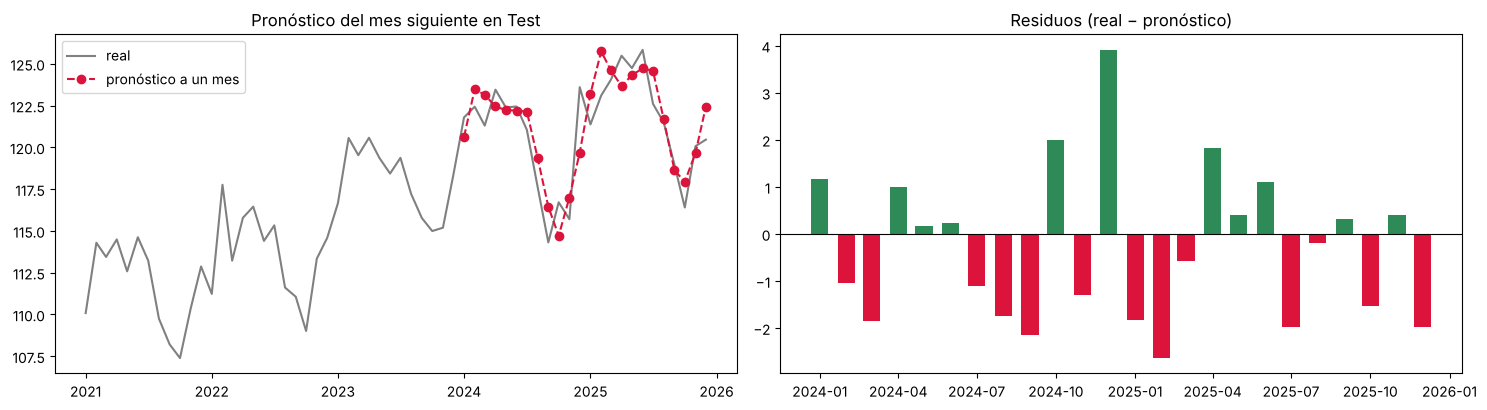

Residuo promedio: -0.30 (cerca de 0 = sin sesgo sistemático)


In [25]:
final = LinearRegression().fit(dev[COLS], dev["objetivo"])           # reentrenar con Train + Validation
pred_te = final.predict(te[COLS])
print(f"Test (ene-2024 a dic-2025) → MAE {mean_absolute_error(te['objetivo'], pred_te):.3f} | RMSE {np.sqrt(mean_squared_error(te['objetivo'], pred_te)):.3f} | MAPE {mean_absolute_percentage_error(te['objetivo'], pred_te):.2%}")
print(f"Línea base ingenua en Test → MAE {mean_absolute_error(te['objetivo'], te['rezago_1']):.3f}")
fechas = te.index + pd.offsets.MonthBegin(1)                         # el mes pronosticado
fig, ax = plt.subplots(1, 2, figsize=(15, 4.2))
ax[0].plot(act["2021":], color="gray", label="real")
ax[0].plot(fechas, pred_te, "o--", color="crimson", label="pronóstico a un mes")
ax[0].set(title="Pronóstico del mes siguiente en Test"); ax[0].legend()
residuos = te["objetivo"].values - pred_te
ax[1].bar(fechas, residuos, width=20, color=["seagreen" if r > 0 else "crimson" for r in residuos])
ax[1].axhline(0, color="black", lw=0.8); ax[1].set(title="Residuos (real − pronóstico)")
plt.tight_layout(); plt.show()
print(f"Residuo promedio: {residuos.mean():+.2f} (cerca de 0 = sin sesgo sistemático)")

**Cómo comunicarlo.** «Con la información disponible a fin de cada mes, el modelo pronostica el índice del mes siguiente con un error típico de 1,35 puntos (≈ 1,1 %), un 35 % menos que repetir el último valor (2,07). No muestra un sesgo sistemático (los residuos se reparten a ambos lados de cero). Es un pronóstico **a un mes**: para horizontes más largos los errores crecen y habría que evaluarlos aparte. Los datos son simulados con fines didácticos.»

**Revisa los residuos:** si fueran casi todos positivos (o negativos), el modelo estaría sesgado; si crecieran con el tiempo, el patrón de la serie estaría cambiando. Aquí se reparten alrededor de cero.

# Parte C · Comparación final: todos los modelos en las cuatro series

Aplicamos **el mismo procedimiento automatizado** a las cuatro series del archivo: misma receta de variables (3 rezagos + rezago 12 + mes), misma división cronológica y cinco modelos. Como cada serie tiene sus propias unidades (puntos, %, dólares, millones), además del MAE calculamos el **MAE relativo a la línea base ingenua**: menos de 1 significa que el modelo mejora a «repetir el último valor».

In [26]:
def evaluar_serie(nombre_serie):
    t = tabla_rezagos(macro[nombre_serie]).dropna()
    tr_, va_, te_ = t[t.index < "2021-12-01"], t[(t.index >= "2021-12-01") & (t.index < "2023-12-01")], t[t.index >= "2023-12-01"]
    preds_va, preds_te = {}, {}
    for k, v in lineas_base(va_).items(): preds_va[k] = v
    for k, v in lineas_base(te_).items(): preds_te[k] = v
    for nombre, crear in modelos.items():
        m = crear().fit(tr_[COLS], tr_["objetivo"])
        preds_va[nombre] = m.predict(va_[COLS])
        m_final = crear().fit(pd.concat([tr_, va_])[COLS], pd.concat([tr_, va_])["objetivo"])     # para Test: reentrenar con Train + Validation
        preds_te[nombre] = m_final.predict(te_[COLS])
    mae_ing = mean_absolute_error(va_["objetivo"], preds_va["Ingenua"])
    filas = [{"serie": nombre_serie, "modelo": k, "MAE_val": mean_absolute_error(va_["objetivo"], p),
              "relativo_a_ingenua": mean_absolute_error(va_["objetivo"], p) / mae_ing,
              "MAE_test": mean_absolute_error(te_["objetivo"], preds_te[k])} for k, p in preds_va.items()]
    return filas

SERIES = ["indice_actividad", "exportaciones_mill", "precio_petroleo_usd", "inflacion_interanual_pct"]
comp = pd.DataFrame([f for s in SERIES for f in evaluar_serie(s)])
print("MAE relativo a la línea base ingenua, en Validation (menor es mejor):")
comp.pivot(index="modelo", columns="serie", values="relativo_a_ingenua")[SERIES].round(2)

MAE relativo a la línea base ingenua, en Validation (menor es mejor):


serie,indice_actividad,exportaciones_mill,precio_petroleo_usd,inflacion_interanual_pct
modelo,,,,
Estacional ingenua,1.52,1.67,2.34,1.80
Ingenua,1.00,1.00,1.00,1.00
Lineal,0.62,0.85,1.18,0.86
Promedio móvil 3,1.11,1.09,0.89,0.87
Random Forest,1.57,1.33,0.98,0.90


In [27]:
ganadores = []
for s in SERIES:
    t = comp[comp["serie"] == s].sort_values("MAE_val")
    g = t.iloc[0]
    ganadores.append({"serie": s, "ganador": g["modelo"], "MAE_val": g["MAE_val"], "relativo_a_ingenua": g["relativo_a_ingenua"],
                      "MAE_test": g["MAE_test"], "MAE_test_ingenua": t[t["modelo"] == "Ingenua"]["MAE_test"].iloc[0]})
pd.DataFrame(ganadores).set_index("serie").round(3)

,ganador,MAE_val,relativo_a_ingenua,MAE_test,MAE_test_ingenua
serie,,,,,
indice_actividad,Lineal,1.286,0.622,1.352,2.066
exportaciones_mill,Lineal,39.217,0.853,36.155,42.411
precio_petroleo_usd,Promedio móvil 3,4.874,0.889,4.723,5.641
inflacion_interanual_pct,Lineal,0.490,0.862,0.498,0.534


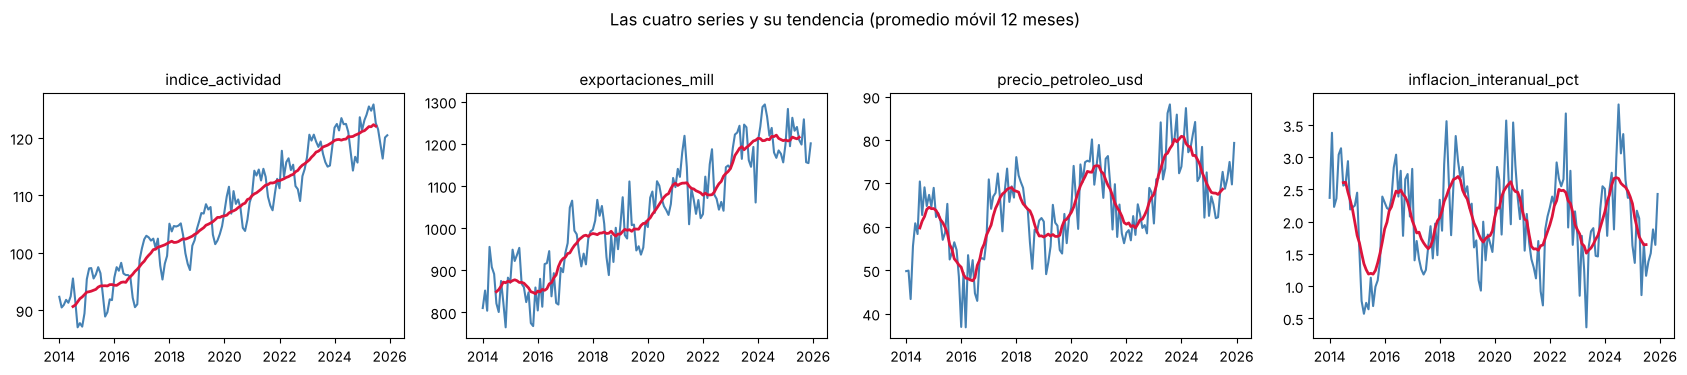

In [28]:
fig, ax = plt.subplots(1, 4, figsize=(17, 3.6))
for a_, s in zip(ax, SERIES):
    a_.plot(macro[s], color="steelblue"); a_.plot(macro[s].rolling(12, center=True).mean(), color="crimson", lw=2)
    a_.set_title(s, fontsize=11)
plt.suptitle("Las cuatro series y su tendencia (promedio móvil 12 meses)", y=1.03); plt.tight_layout(); plt.show()

### ¿Por qué gana un modelo distinto en cada serie?

Mira las cuatro series y su tendencia (en rojo):

- **Índice de actividad y exportaciones** tienen **tendencia y estacionalidad marcadas**: gana la **regresión lineal** con rezagos y calendario, que captura las dos y puede extrapolar la tendencia. El Random Forest queda incluso peor que la línea base ingenua: no extrapola.
- **Precio del petróleo** se mueve como un **paseo aleatorio** alrededor de un nivel, sin estacionalidad: lo mejor es una regla simple de inercia suavizada (el promedio de los últimos meses). Los modelos más complejos no encuentran nada que la regla no tenga ya.
- **Inflación** es muy ruidosa: los modelos apenas mejoran a las reglas simples (MAE relativo cercano a 0,9); la regresión lineal y el promedio móvil quedan prácticamente empatados.
- La **estacional ingenua** es la peor en todas: repetir el valor de hace un año ignora todo lo que pasó en el último año.

**Lecciones del día:**

1. **Un Pipeline guarda todo lo aprendido** (medianas, categorías, medias, el modelo) y se aplica igual a cualquier dato nuevo. Con `joblib` se guarda en un archivo y con una función se automatiza el informe.
2. **En series de tiempo el orden es sagrado:** rezagos con `shift`, objetivo futuro con `shift(-1)` y nunca un predictor del futuro.
3. **División cronológica y `TimeSeriesSplit`:** se entrena con el pasado y se valida con lo que viene después.
4. **Siempre contra una línea base temporal:** ingenua, estacional ingenua o promedio móvil. A veces una regla simple gana (petróleo).
5. **Los bosques no extrapolan tendencias;** la regresión lineal sí. El mejor modelo depende de la forma de la serie.
6. **Para comparar series con unidades distintas,** usa errores relativos a una línea base.

# Actividad autónoma

1. En la Parte A, agrega un paso `StandardScaler` al Pipeline de impago y cambia el modelo por un KNN. ¿Qué tienes que cambiar en la función `informe_semanal`? (Pista: nada.)
2. En la Parte A, cambia el `umbral` de la función a 0,3 y a 0,7. ¿Cuántas solicitudes quedan «a revisar» en cada caso? ¿Qué umbral elegirías si una falsa alarma cuesta poco y un impago mucho?
3. En la Parte B, agrega como predictores el precio del petróleo y las exportaciones **del mes t** (con `shift(0)`, no del futuro). ¿Mejora el pronóstico de la actividad?
4. En la Parte B, pronostica a **3 meses** (objetivo = `shift(-3)`). ¿Cuánto crece el error frente a un mes?
5. Escribe en 150 palabras el mensaje para un comité: qué pronostica el modelo, con qué error, frente a qué línea base y qué limitaciones tiene.